# Search-Rust-NetworkX : graphes et réseaux avec petgraph (Rust)

**Navigation** : [<< Search-02b NetworkX Python](Search-02b-NetworkX.ipynb) | [Index](README.md) | [Search-03c Limited Discrepancy Rust >>](Search-03c-LimitedDiscrepancySearch-Rust.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :

1. Traduire les gestes de `networkx` en Rust idiomatique avec la crate `petgraph`
2. Calculer plus courts chemins (Dijkstra, A*, Bellman-Ford), centralités, flots et modularité sur des graphes réels
3. Nommer ce que l'organe `petgraph` fournit — et ce qu'il laisse à votre charge
4. Lire les écueils de traduction Python -> Rust : propriété et emprunts, graines aléatoires explicites, `Result` à la place des exceptions

**Durée estimée** : ~15 min | **Prérequis** : [Search-02b NetworkX Python](Search-02b-NetworkX.ipynb) | **Lien** : Voir aussi [Search-02c QuikGraph](Search-02c-QuikGraph.ipynb) (jumeau .NET)

***

Ce carnet est le jumeau Rust de [Search-02b NetworkX Python](Search-02b-NetworkX.ipynb) : il reprend la matière complète du carnet Python — construction, prédicats, plus courts chemins, A*, Bellman-Ford, centralités, flot maximum, communautés, matching, et les deux bancs réalistes — avec la crate **`petgraph`** comme organe natif du graphe. Pas de pont Python : chaque cellule est du Rust compilé puis exécuté en place par le kernel **evcxr**, et l'état (variables, types) persiste d'une cellule à l'autre.

La théorie vit dans le jumeau Python ; ici, l'accent est mis sur **l'organe Rust** — ce qu'il calcule pour vous, et ce que le typage vous demande d'écrire vous-même.

## Table des matières

1. [L'organe : la crate petgraph](#1-lorgane-la-crate-petgraph)
2. [Le réseau des six villes](#2-le-reseau-des-six-villes)
3. [Prédicats du graphe](#3-predicats-du-graphe)
4. [La carte du réseau](#4-la-carte-du-reseau)
5. [Plus courts chemins](#5-plus-courts-chemins)
6. [L'heuristique géodésique](#6-lheuristique-geodesique)
7. [Bellman-Ford et poids négatifs](#7-bellman-ford-et-poids-negatifs)
8. [Centralités](#8-centralites)
9. [Flot maximum](#9-flot-maximum)
10. [Communautés et modularité](#10-communautes-et-modularite)
11. [Matching pondéré](#11-matching-pondere)
12. [Grille routière (banc Prong B)](#12-grille-routiere-banc-prong-b)
13. [Réseau de collaborations](#13-reseau-de-collaborations)
14. [Exercices](#14-exercices)

## References

- [petgraph — docs.rs](https://docs.rs/petgraph) — l'organe Rust des graphes
- [NetworkX — documentation](https://networkx.org/documentation/stable/) — le jumeau Python
- [evcxr — le kernel Jupyter Rust](https://github.com/evcxr/evcxr)
- Brandes, *A Faster Algorithm for Betweenness Centrality* (2001) — [arxiv:cond-mat/0109047](https://arxiv.org/abs/cond-mat/0109047)
- Blondel et al., *Fast unfolding of communities in large networks* (2008) — l'algorithme de Louvain


## 1. L'organe : la crate petgraph

Le jumeau Python s'appuie sur `networkx`, qui couvre à lui seul tout le catalogue. En Rust, l'organe est la crate **`petgraph`** : elle fournit la structure de graphe et les algorithmes de chemins — mais elle est plus sobre que networkx, et plusieurs mesures du carnet Python s'y écrivent à la main. La table dit ce qui vient d'où :

| Geste (networkx) | Ce carnet (Rust) | D'où |
|---|---|---|
| `nx.Graph()`, `add_edge` | `Graph::new_undirected()`, `add_edge` | **petgraph** |
| `shortest_path(weight=...)` | `algo::dijkstra` + reconstruction du chemin maison | petgraph (distances seulement) |
| `astar_path(heuristic=...)` | `algo::astar` | **petgraph** |
| `bellman_ford_path` | `algo::bellman_ford` (exige un `DiGraph`) | **petgraph** |
| `pagerank` | `algo::page_rank` (exige un `DiGraph`) | **petgraph** |
| `betweenness/closeness_centrality` | Brandes (2001) réimplémenté | **local** |
| `maximum_flow` + flot par arête | Edmonds-Karp sur matrice résiduelle | **local** |
| `louvain_communities` + `modularity` | modularité exacte, partitions candidates | **local** |
| `max_weight_matching` | énumération exacte des 4! permutations | **local** |

**Ecueils de traduction** (ce que le Rust rend visible, pas coûteux) :

- **La propriété traverse le code** : un graphe passé à un algorithme est emprunté, jamais copié ; les structures partagées se déclarent (`Arc`, `Cell`) au lieu de se deviner.
- **L'aléatoire est un type** : `StdRng` se sème explicitement (`seed_from_u64`), graine par graine — la reproductibilité ne dépend plus d'un état global comme `np.random.seed`.
- **`Result` à la place des exceptions** : `bellman_ford` rend un `Result` car il peut détecter un cycle négatif ; le code gère ce cas au lieu de l'avaler.

**Règle evcxr du carnet** : les fonctions d'une cellule ne sont pas fiablement persistées au-delà, chaque cellule de code est donc autonome (elle redéfinit ce dont elle a besoin) ; les **variables**, elles, persistent.


In [2]:
:dep petgraph = "0.8"
:dep rand = "0.8"
:dep plotters = { version = "0.3", default-features = false, features = ["evcxr", "line_series"] }

## 2. Le réseau des six villes

Le graphe de travail est le même que celui du jumeau Python : six grandes villes françaises, reliées par leurs distances routières (km). Population, région et coordonnées (latitude, longitude) accompagnent chaque ville — en Rust, les attributs ne vivent pas « dans » les nœuds par magie : on tient des tables `HashMap` à côté du graphe, et le poids d'arête de `petgraph` porte la distance.


In [3]:
use std::collections::HashMap;
use petgraph::graph::NodeIndex;
use petgraph::{Graph, Undirected};

// NodeIndex par ordre d'ajout : Paris=0, Lyon=1, Marseille=2, Toulouse=3, Bordeaux=4, Lille=5.
let villes: Vec<&str> = vec!["Paris", "Lyon", "Marseille", "Toulouse", "Bordeaux", "Lille"];

let mut population: HashMap<&str, u32> = HashMap::new();
population.insert("Paris", 2161000);
population.insert("Lyon", 516000);
population.insert("Marseille", 870000);
population.insert("Toulouse", 479000);
population.insert("Bordeaux", 257000);
population.insert("Lille", 234000);

let mut region: HashMap<&str, &str> = HashMap::new();
region.insert("Paris", "IDF");
region.insert("Lyon", "ARA");
region.insert("Marseille", "PAC");
region.insert("Toulouse", "OCC");
region.insert("Bordeaux", "NAQ");
region.insert("Lille", "HDF");

let mut coords: HashMap<&str, (f64, f64)> = HashMap::new(); // (latitude, longitude)
coords.insert("Paris", (48.8566, 2.3522));
coords.insert("Lyon", (45.7640, 4.8357));
coords.insert("Marseille", (43.2965, 5.3698));
coords.insert("Toulouse", (43.6047, 1.4442));
coords.insert("Bordeaux", (44.8378, -0.5792));
coords.insert("Lille", (50.6292, 3.0573));

let mut g: Graph<&str, f64, Undirected> = Graph::new_undirected();
let mut vid: HashMap<&str, NodeIndex> = HashMap::new();
for v in &villes {
    vid.insert(v, g.add_node(v));
}

let liaisons: Vec<(&str, &str, f64)> = vec![
    ("Paris", "Lyon", 465.0),
    ("Paris", "Lille", 225.0),
    ("Paris", "Bordeaux", 585.0),
    ("Lyon", "Marseille", 315.0),
    ("Lyon", "Toulouse", 540.0),
    ("Marseille", "Toulouse", 405.0),
    ("Bordeaux", "Toulouse", 245.0),
];
for (a, b, km) in &liaisons {
    g.add_edge(vid[a], vid[b], *km);
}

println!("graphe : {} noeuds, {} aretes", g.node_count(), g.edge_count());
for (a, b, km) in &liaisons {
    println!("  {} -- {} : {} km", a, b, km);
}

graphe : 6 noeuds, 7 aretes


  Paris -- Lyon : 465 km


  Paris -- Lille : 225 km


  Paris -- Bordeaux : 585 km


  Lyon -- Marseille : 315 km


  Lyon -- Toulouse : 540 km


  Marseille -- Toulouse : 405 km


  Bordeaux -- Toulouse : 245 km


()

## 3. Prédicats du graphe

Avant d'algorithmer, mesurer : degré, degré moyen, densité, diamètre, connexité. Ces quatre chiffres disent quelle famille d'algorithmes est pertinente sur l'instance. Le diamètre se calcule en **sauts** (chaque arête compte 1) : on demande à l'organe `dijkstra` un coût uniforme, et on prend la plus grande excentricité.


In [4]:
use std::collections::HashMap;
use petgraph::algo;

let n = g.node_count();
let m = g.edge_count();

let deg_paris = g.neighbors(vid["Paris"]).count();
let somme_deg: usize = g.node_indices().map(|v| g.neighbors(v).count()).sum();
let deg_moy = somme_deg as f64 / n as f64;
let densite = 2.0 * m as f64 / (n * (n - 1)) as f64;

// Diametre : plus grande excentricite, en sauts (cout 1.0 par arete).
let mut diametre = 0usize;
for v in g.node_indices() {
    let d = algo::dijkstra(&g, v, None, |_| 1.0);
    let ecc = d.values().map(|x| *x as usize).max().unwrap_or(0);
    if ecc > diametre {
        diametre = ecc;
    }
}

println!("{} noeuds, {} aretes", n, m);
println!("degre de Paris : {}", deg_paris);
println!("degre moyen : {:.2}", deg_moy);
println!("densite : {:.3}", densite);
println!("diametre (sauts) : {}", diametre);
println!("composantes connexes : {}", algo::connected_components(&g));

6 noeuds, 7 aretes


degre de Paris : 3


degre moyen : 2.33


densite : 0.467


diametre (sauts) : 3


composantes connexes : 1


### 3.1. Voisinage et sous-graphe induit

Deux gestes de tous les jours : lister les voisins d'un nœud, et extraire le sous-graphe induit par un ensemble de sommets. Le premier est une méthode de `petgraph` ; le second n'existe pas dans l'organe — on le reconstruit : nouveaux `NodeIndex` pour les membres retenus, puis on recopie les arêtes dont les deux extrémités sont dedans.


In [5]:
use std::collections::HashMap;
use petgraph::{Graph, Undirected};
use petgraph::graph::NodeIndex;
use petgraph::visit::EdgeRef;

// Voisinage de Paris, trie par nom pour un affichage deterministe.
let mut voisins: Vec<&str> = g.neighbors(vid["Paris"]).map(|v| g[v]).collect();
voisins.sort();
println!("voisins de Paris ({}) : {:?}", voisins.len(), voisins);

// Sous-graphe induit : Paris + ses voisins.
let mut membres: Vec<&str> = vec!["Paris"];
membres.extend(voisins.iter().copied());
membres.sort();

let mut sous: Graph<&str, f64, Undirected> = Graph::new_undirected();
let mut sidx: HashMap<&str, NodeIndex> = HashMap::new();
for nom in &membres {
    sidx.insert(nom, sous.add_node(nom));
}
for e in g.edge_references() {
    let (a, b, w) = (g[e.source()], g[e.target()], *e.weight());
    if let (Some(&na), Some(&nb)) = (sidx.get(a), sidx.get(b)) {
        sous.add_edge(na, nb, w);
    }
}
println!("sous-graphe Paris + voisins : {} noeuds, {} aretes", sous.node_count(), sous.edge_count());

voisins de Paris (3) : ["Bordeaux", "Lille", "Lyon"]


sous-graphe Paris + voisins : 4 noeuds, 3 aretes


## 4. La carte du réseau

Même geste que `nx.draw_networkx` côté Python, avec `plotters` côté Rust : projection simple (longitude, latitude) vers des pixels, une ligne grise par arête, un disque par ville dont le rayon croît comme la racine de la population. La feature `evcxr` de `plotters` émet le SVG en place ; sans la feature `ttf` (elle exigerait une dépendance système de polices), la figure ne porte pas de texte — la légende vit dans cette phrase et dans la cellule suivante.


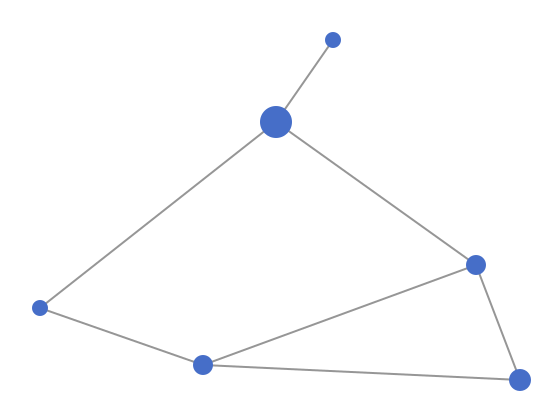

In [6]:
use plotters::prelude::*;
use std::collections::HashMap;
use petgraph::visit::EdgeRef;

// Carte des 6 villes : (longitude, latitude) -> pixels, rayon ~ sqrt(population).
let pop_max = 2161000.0_f64;
let (w_px, h_px) = (560u32, 420u32);

// Projection geographique : fonction libre (evcxr exige 'static pour les closures).
fn proj_geo(nom: &str, coords: &HashMap<&str, (f64, f64)>) -> (i32, i32) {
    let (w_px, h_px, marge) = (560u32, 420u32, 40u32);
    let (lon_min, lon_max) = (-0.5792_f64, 5.3698_f64);
    let (lat_min, lat_max) = (43.2965_f64, 50.6292_f64);
    let (la, lo) = coords[nom];
    let x = marge as f64 + (lo - lon_min) / (lon_max - lon_min) * (w_px - 2 * marge) as f64;
    let y = marge as f64 + (lat_max - la) / (lat_max - lat_min) * (h_px - 2 * marge) as f64;
    (x as i32, y as i32)
}

let mut svg = String::new();
{
    let root = SVGBackend::with_string(&mut svg, (w_px, h_px)).into_drawing_area();
    root.fill(&WHITE)?;
    for e in g.edge_references() {
        let (a, b) = (g[e.source()], g[e.target()]);
        let (xa, ya) = proj_geo(a, &coords);
        let (xb, yb) = proj_geo(b, &coords);
        root.draw(&PathElement::new(vec![(xa, ya), (xb, yb)], RGBColor(150, 150, 150).stroke_width(2)))?;
    }
    for v in g.node_indices() {
        let nom = g[v];
        let (x, y) = proj_geo(nom, &coords);
        let r = 5.0 + 11.0 * (population[nom] as f64 / pop_max).sqrt();
        root.draw(&Circle::new((x, y), r as u32, RGBColor(70, 110, 200).filled()))?;
    }
    root.present()?;
}
println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);

### Lecture de la figure

La géographie est restée intacte : Lille au nord, Marseille et Toulouse au sud, et Paris au centre du réseau comme au centre du territoire. La taille des disques dit la population — Paris domine nettement — mais la **structure** du graphe ne dépend pas des populations : ce sont les sept arêtes qui décident des chemins, et l'oeil voit déjà que Paris est le seul carrefour entre le nord (Lille) et le sud (Lyon, Bordeaux), tandis que l'axe méditerranéen Lyon-Marseille-Toulouse forme un triangle à part. C'est exactement ce que la betweenness de la section 8 chiffrera.


## 5. Plus courts chemins

L'organe `algo::dijkstra` rend une table de **distances**, pas un chemin : la reconstruction est à notre charge. On remonte depuis la cible de prédécesseur en prédécesseur — un voisin `u` est prédécesseur de `courant` si `dist(u) + poids(u, courant) = dist(courant)` (à epsilon près). En cas d'égalité parfaite, le tie-break prend le plus petit `NodeIndex` : le résultat est déterministe d'une exécution à l'autre, ce qui n'est pas garanti sinon.

Le même service, appelé deux fois : pondéré (kilomètres), puis non pondéré (chaque arête compte 1).


In [7]:
use std::collections::HashMap;
use petgraph::{algo, Graph, Undirected};
use petgraph::graph::NodeIndex;

fn chemin_min(g: &Graph<&str, f64, Undirected>, source: NodeIndex, cible: NodeIndex) -> Option<(f64, Vec<String>)> {
    let dist = algo::dijkstra(g, source, Some(cible), |e| *e.weight());
    let dcible = *dist.get(&cible)?;
    let mut chemin: Vec<String> = vec![g[cible].to_string()];
    let mut courant = cible;
    while courant != source {
        let dc = *dist.get(&courant)?;
        let mut meilleur: Option<NodeIndex> = None;
        for e in g.edges(courant) {
            let u = e.target();
            let du = *dist.get(&u).unwrap_or(&f64::INFINITY);
            if (du + *e.weight() - dc).abs() < 1e-9 {
                if meilleur.map_or(true, |m| u.index() < m.index()) {
                    meilleur = Some(u);
                }
            }
        }
        courant = meilleur?;
        chemin.push(g[courant].to_string());
    }
    chemin.reverse();
    Some((dcible, chemin))
}

{
    let (km, chemin) = chemin_min(&g, vid["Paris"], vid["Toulouse"]).unwrap_or((0.0, Vec::new()));
    println!("Paris -> Toulouse (pondere, km) : {:.0} km via {:?}", km, chemin);
    let (km2, chemin2) = chemin_min(&g, vid["Paris"], vid["Marseille"]).unwrap_or((0.0, Vec::new()));
    println!("Paris -> Marseille (pondere, km) : {:.0} km via {:?}", km2, chemin2);
}

Paris -> Toulouse (pondere, km) : 830 km via ["Paris", "Bordeaux", "Toulouse"]


Paris -> Marseille (pondere, km) : 780 km via ["Paris", "Lyon", "Marseille"]


()

### 5.1. Non pondéré : compter les sauts

Même fonction, même graphe — seul le coût change : chaque arête vaut 1. Le « plus court chemin » devient le chemin qui minimise le **nombre de correspondances**, pas les kilomètres.


In [8]:
use std::collections::HashMap;
use petgraph::{algo, Graph, Undirected};
use petgraph::graph::NodeIndex;

// Copie de chemin_min avec un cout uniforme (la cellule est autonome).
fn chemin_sauts(g: &Graph<&str, f64, Undirected>, source: NodeIndex, cible: NodeIndex) -> Option<(f64, Vec<String>)> {
    let dist = algo::dijkstra(g, source, Some(cible), |_| 1.0);
    let dcible = *dist.get(&cible)?;
    let mut chemin: Vec<String> = vec![g[cible].to_string()];
    let mut courant = cible;
    while courant != source {
        let dc = *dist.get(&courant)?;
        let mut meilleur: Option<NodeIndex> = None;
        for e in g.edges(courant) {
            let u = e.target();
            let du = *dist.get(&u).unwrap_or(&f64::INFINITY);
            if (du + 1.0 - dc).abs() < 1e-9 {
                if meilleur.map_or(true, |m| u.index() < m.index()) {
                    meilleur = Some(u);
                }
            }
        }
        courant = meilleur?;
        chemin.push(g[courant].to_string());
    }
    chemin.reverse();
    Some((dcible, chemin))
}

{
    let (sauts, chemin) = chemin_sauts(&g, vid["Paris"], vid["Toulouse"]).unwrap_or((0.0, Vec::new()));
    println!("Paris -> Toulouse (sauts) : {} sauts via {:?}", sauts as usize, chemin);
}

Paris -> Toulouse (sauts) : 2 sauts via ["Paris", "Lyon", "Toulouse"]


()

### Lecture du résultat — le poids décide de la géographie

Les deux sorties ci-dessus donnent **deux réponses différentes à la même question**. En kilomètres, Paris -> Toulouse passe par Bordeaux (585 + 245 = 830 km) ; en sauts, il passe par Lyon (2 correspondances). Aucun des deux n'est « le » plus court chemin : minimiser des kilomètres ou des correspondances sont deux optimisations distinctes, et le même graphe les arbitre différemment. Vers Marseille en revanche, les deux critères s'accordent sur Lyon — et l'on peut vérifier à la main que 465 + 315 = 780 km est bien mieux que le détour par Toulouse.

C'est le premier enseignement de tout cours sur les graphes pondérés : **le poids est une décision de modélisation**, pas un détail.


## 6. L'heuristique géodésique

A* est le second organe de chemins de `petgraph` : `algo::astar` prend, en plus de Dijkstra, une fonction d'estimation `h(n)` du coût restant. Ici, l'estimation est la distance à vol d'oiseau (formule de l'haversine, rayon terrestre 6371 km) : elle est **admissible** — la ligne droite ne surestime jamais la route — donc A* conserve la garantie d'optimalité de Dijkstra.


In [9]:
use std::collections::HashMap;
use petgraph::{algo};
use petgraph::graph::NodeIndex;

fn haversine_km(a: (f64, f64), b: (f64, f64)) -> f64 {
    let (la1, lo1) = (a.0.to_radians(), a.1.to_radians());
    let (la2, lo2) = (b.0.to_radians(), b.1.to_radians());
    let dla = la2 - la1;
    let dlo = lo2 - lo1;
    let h = (dla / 2.0).sin().powi(2) + la1.cos() * la2.cos() * (dlo / 2.0).sin().powi(2);
    2.0 * 6371.0 * h.sqrt().asin()
}

{
    let marseille = vid["Marseille"];
    let cible = coords["Marseille"];
    let res = algo::astar(
        &g,
        vid["Paris"],
        |v| v == marseille,
        |e| *e.weight(),
        |v| haversine_km(coords[g[v]], cible),
    );

    let vol = haversine_km(coords["Paris"], coords["Marseille"]);
    let dmin = algo::dijkstra(&g, vid["Paris"], None, |e| *e.weight());
    let droute = dmin.get(&marseille).copied().unwrap_or(0.0);

    if let Some((cout, chemin)) = res {
        let noms: Vec<&str> = chemin.iter().map(|v| g[*v]).collect();
        println!("A* Paris -> Marseille : {:.0} km via {:?}", cout, noms);
        println!("vol d'oiseau Paris -> Marseille : {:.1} km", vol);
        println!("dijkstra (verite terrain) : {:.0} km", droute);
        println!("admissible : vol <= route : {}", vol <= droute + 1e-9);
    } else {
        println!("aucun chemin trouve");
    }
}

A* Paris -> Marseille : 780 km via ["Paris", "Lyon", "Marseille"]


vol d'oiseau Paris -> Marseille : 660.5 km


dijkstra (verite terrain) : 780 km


admissible : vol <= route : true


()

### Lecture du résultat — l'admissibilité ne coûte rien

A* et Dijkstra rendent le même coût (780 km par Lyon) : c'est la garantie que donne l'heuristique admissible. La valeur intermédiaire est la plus parlante : le vol d'oiseau (~661 km) est **inférieur** à la route (780 km), toujours — la ligne droite est le plus court chemin possible dans le plan, aucune route ne peut faire mieux. C'est cette inégalité, vraie pour chaque nœud, qui tient la preuve d'optimalité de A* : l'estimation ne « triche » jamais vers un chemin sous-optimal. Une heuristique qui surestimerait (vol d'oiseau multiplié par 2, par exemple) irait plus vite mais pourrait rater l'optimum.

Sur six villes, l'économie de nœuds explorés est modeste ; la section 12 la mesure pour de bon sur une grille 25 nœuds bruitée.


## 7. Bellman-Ford et poids négatifs

Dijkstra interdit les poids négatifs ; Bellman-Ford les accepte et **détecte les cycles négatifs** — c'est précisément pourquoi son type de retour est un `Result` en Rust : le cas d'échec fait partie du contrat, là où Python lèverait une exception. L'organe `petgraph` ne l'offre que sur les graphes **dirigés** : on symétrise donc le réseau (chaque route devient deux arcs), et on vérifie que les distances rendues coïncident avec celles de Dijkstra — témoin croisé entre deux organes.


In [10]:
use std::collections::HashMap;
use std::hint::black_box;
use std::time::Instant;
use petgraph::{algo, Graph, Directed};
use petgraph::graph::NodeIndex;
use petgraph::visit::EdgeRef;

// Symetriser : Bellman-Ford exige un DiGraph.
let mut d: Graph<&str, f64, Directed> = Graph::new();
let mut did: HashMap<&str, NodeIndex> = HashMap::new();
for v in &villes {
    did.insert(v, d.add_node(v));
}
for e in g.edge_references() {
    let (a, b, w) = (g[e.source()], g[e.target()], *e.weight());
    d.add_edge(did[a], did[b], w);
    d.add_edge(did[b], did[a], w);
}

{
    let bf = algo::bellman_ford(&d, did["Paris"]);
    let dist_bf: Vec<f64> = match &bf {
        Ok(paths) => paths.distances.clone(),
        Err(_) => vec![f64::NAN; d.node_count()],
    };
    let dist_dij = algo::dijkstra(&g, vid["Paris"], None, |e| *e.weight());

    let mut identiques = true;
    for v in g.node_indices() {
        let dd = dist_dij.get(&v).copied().unwrap_or(f64::INFINITY);
        if (dd - dist_bf[v.index()]).abs() > 1e-6 {
            identiques = false;
        }
    }

    println!("graphe dirige symetrise : {} aretes", d.edge_count());
    for v in g.node_indices() {
        println!(
            "  {:<10} dijkstra {:>6.0} km   bellman-ford {:>6.0} km",
            g[v],
            dist_dij.get(&v).copied().unwrap_or(0.0),
            dist_bf[v.index()]
        );
    }
    println!("distances identiques : {}", identiques);

    // Chrono RELATIF (rapport, pas millisecondes absolues).
    const ITER: usize = 10_000;
    let t0 = Instant::now();
    for _ in 0..ITER {
        let dd = algo::dijkstra(&g, vid["Paris"], None, |e| *e.weight());
        black_box(&dd);
    }
    let t_dij = t0.elapsed();
    let t1 = Instant::now();
    for _ in 0..ITER {
        if let Ok(r) = algo::bellman_ford(&d, did["Paris"]) {
            black_box(&r);
        }
    }
    let t_bf = t1.elapsed();
    println!(
        "{} iterations : rapport bellman-ford / dijkstra = {:.1}x",
        ITER,
        t_bf.as_secs_f64() / t_dij.as_secs_f64()
    );
}

graphe dirige symetrise : 14 aretes


  Paris      dijkstra      0 km   bellman-ford      0 km


  Lyon       dijkstra    465 km   bellman-ford    465 km


  Marseille  dijkstra    780 km   bellman-ford    780 km


  Toulouse   dijkstra    830 km   bellman-ford    830 km


  Bordeaux   dijkstra    585 km   bellman-ford    585 km


  Lille      dijkstra    225 km   bellman-ford    225 km


distances identiques : true


10000 iterations : rapport bellman-ford / dijkstra = 0.3x


()

### Lecture du résultat — le prix de la généralité

Les deux colonnes coïncident ville par ville : sur un graphe sans poids négatif, Bellman-Ford rend exactement les distances de Dijkstra. La différence attendue est la **complexité** : Dijkstra avec une file de priorité coûte typiquement O((|V|+|E|) log |V|), tandis que Bellman-Ford détend toutes les arêtes |V|-1 fois, soit O(|V||E|). Le rapport de temps affiché ci-dessus n'est qu'un **micro-banc local**, très sensible à la taille du graphe, à l'optimisation et aux allocations ; sur six villes, il ne faut pas le lire comme une mesure de ce surcoût asymptotique. La règle pratique s'écrit toute seule : Bellman-Ford quand les poids peuvent être négatifs (ou pour détecter un cycle négatif via son `Result`), Dijkstra sinon.


## 8. Centralités

Quatre mesures, quatre questions. La centralité de degré compte les connexions directes ; la **betweenness** compte la fraction des plus courts chemins qui transitent par le nœud (le rôle de *broker*) ; la **closeness** mesure la distance moyenne aux autres ; le **PageRank** propage l'importance le long des liens. Degré et closeness sont des recettes de trois lignes ; la betweenness demande l'algorithme de Brandes (2001) — elle n'est pas dans `petgraph` — et le PageRank exige le graphe dirigé de la section suivante.


In [11]:
use std::collections::HashMap;
use petgraph::{algo, Graph, Undirected};
use petgraph::graph::NodeIndex;
use petgraph::visit::EdgeRef;

// Brandes (2001), generique sur le type de noeud, pondere ou non.
// Normalisation networkx pour un graphe non oriente : cb(v) = brut / ((n-1)(n-2)).
fn betweenness<N>(g: &Graph<N, f64, Undirected>, pondere: bool) -> HashMap<NodeIndex, f64> {
    let n = g.node_count();
    let mut cb: HashMap<NodeIndex, f64> = g.node_indices().map(|v| (v, 0.0)).collect();
    for s in g.node_indices() {
        let dist = algo::dijkstra(g, s, None, |e| if pondere { *e.weight() } else { 1.0 });
        let mut atteints: Vec<NodeIndex> = dist.keys().copied().collect();
        atteints.sort_by(|a, b| {
            dist[a]
                .partial_cmp(&dist[b])
                .unwrap_or(std::cmp::Ordering::Equal)
                .then(a.index().cmp(&b.index()))
        });
        let mut sigma: HashMap<NodeIndex, f64> = g.node_indices().map(|v| (v, 0.0)).collect();
        sigma.insert(s, 1.0);
        let mut preds: HashMap<NodeIndex, Vec<NodeIndex>> = HashMap::new();
        for u in &atteints {
            let du = dist[u];
            for e in g.edges(*u) {
                let w = e.target();
                let wgt = if pondere { *e.weight() } else { 1.0 };
                let dw = dist.get(&w).copied().unwrap_or(f64::INFINITY);
                if (dw - (du + wgt)).abs() < 1e-9 {
                    *sigma.entry(w).or_insert(0.0) += sigma[u];
                    preds.entry(w).or_default().push(*u);
                }
            }
        }
        let mut delta: HashMap<NodeIndex, f64> = g.node_indices().map(|v| (v, 0.0)).collect();
        for u in atteints.iter().rev() {
            for p in preds.get(u).cloned().unwrap_or_default() {
                *delta.entry(p).or_insert(0.0) += sigma[&p] / sigma[u] * (1.0 + delta[u]);
            }
            if *u != s {
                *cb.entry(*u).or_insert(0.0) += delta[u];
            }
        }
    }
    for v in cb.values_mut() {
        *v /= ((n - 1) * (n - 2)) as f64;
    }
    cb
}

let n_v = g.node_count();
let bet = betweenness(&g, true);

let clo: HashMap<NodeIndex, f64> = g
    .node_indices()
    .map(|v| {
        let d = algo::dijkstra(&g, v, None, |_| 1.0);
        let total: f64 = d.values().sum();
        (v, ((d.len() - 1) as f64) / total)
    })
    .collect();

println!("{:<10} {:>8} {:>10} {:>11}", "Ville", "Degree", "Between.", "Closeness");
for v in g.node_indices() {
    let deg = g.neighbors(v).count() as f64 / (n_v - 1) as f64;
    println!("{:<10} {:>8.3} {:>10.3} {:>11.3}", g[v], deg, bet[&v], clo[&v]);
}

Ville        Degree   Between.   Closeness


Paris         0.600      0.400       0.714


Lyon          0.600      0.200       0.714


Marseille     0.400      0.000       0.556


Toulouse      0.600      0.200       0.625


Bordeaux      0.400      0.200       0.625


Lille         0.200      0.000       0.455


()

### 8.1. PageRank

L'organe `algo::page_rank` exige un graphe **dirigé** : un réseau d'amitié non orienté se symétrise (chaque lien devient deux arcs), ce qui évite au passage les nœuds pendants du point de vue du flux. Le vecteur rendu est indexé par `NodeIndex` — à nous de le raccrocher aux noms.


In [12]:
use std::collections::HashMap;
use petgraph::{algo, Graph, Directed};
use petgraph::graph::NodeIndex;
use petgraph::visit::EdgeRef;

let mut d: Graph<&str, (), Directed> = Graph::new();
let mut did: HashMap<&str, NodeIndex> = HashMap::new();
for v in &villes {
    did.insert(v, d.add_node(v));
}
for e in g.edge_references() {
    let (a, b) = (g[e.source()], g[e.target()]);
    d.add_edge(did[a], did[b], ());
    d.add_edge(did[b], did[a], ());
}

let pr = algo::page_rank(&d, 0.85_f32, 100);
let mut classe: Vec<(f32, &str)> = g.node_indices().map(|v| (pr[v.index()], g[v])).collect();
classe.sort_by(|x, y| {
    y.0.partial_cmp(&x.0)
        .unwrap_or(std::cmp::Ordering::Equal)
        .then(x.1.cmp(y.1))
});

println!("{:<10} {:>10}", "Ville", "PageRank");
for (s, nom) in &classe {
    println!("{:<10} {:>10.4}", nom, s);
}

Ville        PageRank


Paris          0.2218


Toulouse       0.2038


Lyon           0.2035


Bordeaux       0.1441


Marseille      0.1390


Lille          0.0879


()

### Lecture du résultat — choisir la centralité, c'est choisir la question

Le tableau des trois premières mesures est le point d'ancrage : **elles ne classent pas les villes dans le même ordre**. Le degré (0.600) est partagé par Paris, Lyon et Toulouse — les trois nœuds à trois arêtes — et ne distingue pas un carrefour d'un nœud simplement bien connecté. La betweenness les sépare nettement : Paris monte seul en tête (0.400), car c'est lui que traversent les plus courts chemins vers Lille et Bordeaux, tandis que Marseille et Lille tombent à 0.000 — des **extrémités**, on y arrive mais on n'y transite pas. La closeness (Paris et Lyon à 0.714) mesure l'inverse : la proximité moyenne à tous les autres.

Le PageRank (section 8.1) confirme la hiérarchie de popularité : Paris domine, Lyon et Toulouse suivent. Sur ce petit graphe dense, les quatre mesures concordent à peu près — la section 13 montrera un réseau réaliste où elles divergent franchement, et pourquoi c'est précisément là qu'elles deviennent informatives.


## 9. Flot maximum

Le réseau de transport du jumeau Python : deux usines, trois dépôts, deux clients, une source et un puits, capacités en tonnes/jour. L'organe `petgraph` expose `ford_fulkerson`, qui ne rend que la **valeur** du flot — pas sa répartition par arête. Or la répartition est l'information opérationnelle (où se serreront les capacités ?) : on implémente donc **Edmonds-Karp** (Ford-Fulkerson en BFS) sur une matrice résiduelle dense 9 x 9. Après saturation, `capacite - residuel` redonne le flot de chaque arête.


In [13]:
// Reseau de transport : capacites en tonnes/jour.
// Indices : 0 Source, 1 Usine_A, 2 Usine_B, 3 Depot_1, 4 Depot_2, 5 Depot_3,
//           6 Client_X, 7 Client_Y, 8 Puits.
let noms_flot: Vec<&str> = vec![
    "Source", "Usine_A", "Usine_B", "Depot_1", "Depot_2", "Depot_3", "Client_X", "Client_Y", "Puits",
];
let caps: Vec<(usize, usize, f64)> = vec![
    (0, 1, 50.0),
    (0, 2, 40.0),
    (1, 3, 30.0),
    (1, 4, 20.0),
    (2, 4, 25.0),
    (2, 5, 15.0),
    (3, 6, 25.0),
    (3, 7, 10.0),
    (4, 6, 15.0),
    (4, 7, 20.0),
    (5, 7, 15.0),
    (6, 8, 50.0),
    (7, 8, 50.0),
];

fn edmonds_karp(res: &mut Vec<Vec<f64>>, s: usize, t: usize) -> f64 {
    let n = res.len();
    let mut flot = 0.0;
    loop {
        let mut parent: Vec<usize> = vec![usize::MAX; n];
        let mut file: std::collections::VecDeque<usize> = std::collections::VecDeque::new();
        parent[s] = s;
        file.push_back(s);
        while let Some(u) = file.pop_front() {
            if u == t {
                break;
            }
            for v in 0..n {
                if parent[v] == usize::MAX && res[u][v] > 1e-12 {
                    parent[v] = u;
                    file.push_back(v);
                }
            }
        }
        if parent[t] == usize::MAX {
            return flot; // plus de chemin augmentant
        }
        let mut goulot = f64::INFINITY;
        let mut v = t;
        while v != s {
            let u = parent[v];
            goulot = goulot.min(res[u][v]);
            v = u;
        }
        let mut v = t;
        while v != s {
            let u = parent[v];
            res[u][v] -= goulot;
            res[v][u] += goulot;
            v = u;
        }
        flot += goulot;
    }
}

let mut res: Vec<Vec<f64>> = vec![vec![0.0; 9]; 9];
for &(u, v, c) in &caps {
    res[u][v] = c;
}
let fmax = edmonds_karp(&mut res, 0, 8);
println!("flot maximum : {:.0} tonnes/jour", fmax);
println!("aretes utilisees (flot/capacite) :");
for &(u, v, c) in &caps {
    let f = c - res[u][v];
    if f > 1e-9 {
        let sat = if (f - c).abs() < 1e-9 { "  (saturee)" } else { "" };
        println!("  {:<10} -> {:<10} : {:>4.0}/{:.0}{}", noms_flot[u], noms_flot[v], f, c, sat);
    }
}

flot maximum : 80 tonnes/jour


aretes utilisees (flot/capacite) :


  Source     -> Usine_A    :   50/50  (saturee)


  Source     -> Usine_B    :   30/40


  Usine_A    -> Depot_1    :   30/30  (saturee)


  Usine_A    -> Depot_2    :   20/20  (saturee)


... (6 outputs left out)

  Depot_3    -> Client_Y   :   15/15  (saturee)


  Client_X   -> Puits      :   40/50


  Client_Y   -> Puits      :   40/50


()

### 9.1. Saturée ne veut pas dire contraignante

Une arête saturée (flot = capacité) n'est un vrai goulot que si elle appartient la **coupe minimale** — l'ensemble d'arêtes dont la capacité totale borne le flot. Le test est mécanique : +1 de capacité sur une arête saturée, puis on relit le flot maximum. Trois candidats, trois verdicts.


In [14]:
// Rejeu : la cellule est autonome, edmonds_karp y est recopiee.
fn edmonds_karp(res: &mut Vec<Vec<f64>>, s: usize, t: usize) -> f64 {
    let n = res.len();
    let mut flot = 0.0;
    loop {
        let mut parent: Vec<usize> = vec![usize::MAX; n];
        let mut file: std::collections::VecDeque<usize> = std::collections::VecDeque::new();
        parent[s] = s;
        file.push_back(s);
        while let Some(u) = file.pop_front() {
            if u == t {
                break;
            }
            for v in 0..n {
                if parent[v] == usize::MAX && res[u][v] > 1e-12 {
                    parent[v] = u;
                    file.push_back(v);
                }
            }
        }
        if parent[t] == usize::MAX {
            return flot;
        }
        let mut goulot = f64::INFINITY;
        let mut v = t;
        while v != s {
            let u = parent[v];
            goulot = goulot.min(res[u][v]);
            v = u;
        }
        let mut v = t;
        while v != s {
            let u = parent[v];
            res[u][v] -= goulot;
            res[v][u] += goulot;
            v = u;
        }
        flot += goulot;
    }
}

fn valeur_flot(caps: &[(usize, usize, f64)], plus_un: (usize, usize)) -> f64 {
    let mut res: Vec<Vec<f64>> = vec![vec![0.0; 9]; 9];
    for &(u, v, c) in caps {
        res[u][v] = c;
    }
    res[plus_un.0][plus_un.1] += 1.0;
    edmonds_karp(&mut res, 0, 8)
}

for (nom, uv) in [
    ("Depot_2 -> Client_X", (4usize, 6usize)),
    ("Usine_A -> Depot_1", (1usize, 3usize)),
    ("Depot_1 -> Client_X", (3usize, 6usize)),
] {
    println!("+1 sur {:<20} : flot maximum = {:.0} (base = 80)", nom, valeur_flot(&caps, uv));
}

+1 sur Depot_2 -> Client_X  : flot maximum = 81 (base = 80)


+1 sur Usine_A -> Depot_1   : flot maximum = 81 (base = 80)


+1 sur Depot_1 -> Client_X  : flot maximum = 80 (base = 80)


()

### Lecture du résultat — le flot maximum se lit sur les goulots

Le flot maximum est de **80 tonnes/jour**. La répartition arête par arête raconte ce que le chiffre global ne dit pas. D'abord les arêtes **saturées** : les deux sorties de l'usine A, `Usine_B -> Depot_3`, les deux sorties du dépôt 2, `Depot_1 -> Client_X` et `Depot_3 -> Client_Y` sont à flot = capacité. **Saturée ne veut pas dire contraignante** : le rejeu le tranche — +1 sur `Depot_2 -> Client_X` ou sur `Usine_A -> Depot_1` porte le flot à **81**, tandis que +1 sur `Depot_1 -> Client_X` ne change rien : l'approvisionnement s'arrête en amont. Une coupe minimale explicite est rive S = {Source, Usine_A, Usine_B, Depot_2} : ses arêtes sortantes sont `Usine_A -> Depot_1` (30), `Usine_B -> Depot_3` (15), `Depot_2 -> Client_X` (15) et `Depot_2 -> Client_Y` (20), soit 30 + 15 + 15 + 20 = 80, exactement le flot maximum (théorème max-flow / min-cut). Ensuite une **source sous-exploitée** : `Source -> Usine_B` ne passe que 30 sur 40 — la capacité de production de B n'est pas la limite, c'est le réseau en aval qui ne l'absorbe pas. C'est la signature d'un flot maximum : en amont des goulots, de la capacité reste inutilisée. (La répartition fine entre deux arêtes également empruntables — ici D1 vers X ou Y — dépend de l'ordre de découverte des chemins augmentants ; la valeur du flot et les saturations structurelles, elles, n'en dépendent pas.)


## 10. Communautés et modularité

Le réseau social du jumeau Python : quatorze personnes, trois équipes (IA, Bio, Physique) reliées intérieurement, plus quelques liens inter-équipes. **Il n'existe pas de Louvain en Rust** — aucun crate mûr ne maximise la modularité. Ce qui se calcule exactement, en revanche, c'est la **modularité** de Newman d'une partition donnée : Q = somme des [L_c/m - (D_c/2m)^2], positive quand les arêtes tombent davantage à l'intérieur des communautés que le hasard ne le prédit. On l'applique à plusieurs partitions candidates — dont celle que Louvain trouve côté Python — et on laisse les chiffres décider.


In [15]:
use std::collections::{HashMap, HashSet};
use petgraph::{Graph, Undirected};
use petgraph::graph::NodeIndex;
use petgraph::visit::EdgeRef;

let mut social: Graph<&str, f64, Undirected> = Graph::new_undirected();
let mut sid: HashMap<&str, NodeIndex> = HashMap::new();
for p in [
    "Alice", "Bob", "Charlie", "Diana", "Eve", "Frank", "Grace", "Hugo", "Iris", "Jules",
    "Karim", "Lea", "Mehdi", "Nora",
] {
    sid.insert(p, social.add_node(p));
}
for (a, b) in [
    // equipe IA
    ("Alice", "Bob"), ("Alice", "Charlie"), ("Bob", "Charlie"), ("Bob", "Diana"),
    ("Charlie", "Diana"), ("Diana", "Eve"),
    // equipe Bio
    ("Frank", "Grace"), ("Grace", "Hugo"), ("Frank", "Hugo"), ("Grace", "Iris"),
    ("Hugo", "Iris"), ("Iris", "Jules"),
    // equipe Physique
    ("Karim", "Lea"), ("Lea", "Mehdi"), ("Karim", "Mehdi"), ("Mehdi", "Nora"),
    ("Nora", "Karim"),
    // liens inter-equipes
    ("Alice", "Frank"), ("Eve", "Jules"), ("Lea", "Nora"),
] {
    social.add_edge(sid[&a], sid[&b], 1.0);
}

fn modularite(g: &Graph<&str, f64, Undirected>, partition: &[Vec<&str>]) -> f64 {
    let m = g.edge_count() as f64;
    if m == 0.0 {
        return 0.0;
    }
    let mut q = 0.0;
    for comm in partition {
        let membres: HashSet<&str> = comm.iter().copied().collect();
        let lc = g
            .edge_references()
            .filter(|e| membres.contains(g[e.source()]) && membres.contains(g[e.target()]))
            .count() as f64;
        let dc: usize = g
            .node_indices()
            .filter(|v| membres.contains(g[*v]))
            .map(|v| g.neighbors(v).count())
            .sum();
        let d2m = dc as f64 / (2.0 * m);
        q += lc / m - d2m * d2m;
    }
    q
}

let p_equipes = vec![
    vec!["Alice", "Bob", "Charlie", "Diana", "Eve"],
    vec!["Frank", "Grace", "Hugo", "Iris", "Jules"],
    vec!["Karim", "Lea", "Mehdi", "Nora"],
];
let p_louvain = vec![
    vec!["Alice", "Bob", "Charlie", "Diana"],
    vec!["Eve", "Jules"],
    vec!["Frank", "Grace", "Hugo", "Iris"],
    vec!["Karim", "Lea", "Mehdi", "Nora"],
];
let p_tout = vec![vec![
    "Alice", "Bob", "Charlie", "Diana", "Eve", "Frank", "Grace", "Hugo", "Iris", "Jules",
    "Karim", "Lea", "Mehdi", "Nora",
]];

println!("reseau social : {} personnes, {} liens", social.node_count(), social.edge_count());
println!("Q (3 equipes revelees)     : {:.3}", modularite(&social, &p_equipes));
println!("Q (equipes + binome E-J)   : {:.3}", modularite(&social, &p_louvain));
println!("Q (tout-en-un)             : {:.3}", modularite(&social, &p_tout));

reseau social : 14 personnes, 20 liens


Q (3 equipes revelees)     : 0.565


Q (equipes + binome E-J)   : 0.570


Q (tout-en-un)             : 0.000


### Lecture du résultat — la modularité tranche, Louvain chercherait

Les trois partitions candidates ne valent pas la même chose. Le tout-en-un vaut exactement 0 (aucune arête n'est « interne » de manière surprenante). Les trois équipes révélées font mieux. Et la partition à quatre blocs — les trois équipes plus le binôme `Eve`-`Jules` — fait encore mieux : ces deux-là ne tenaient à leur équipe respective que par un lien unique, que le lien inter-équipes `Eve - Jules` a emporté. C'est exactement la décision que Louvain prend côté Python (la partition affichée par le jumeau), et la modularité explique **pourquoi** : regrouper les deux marginaux coûte moins que de les ranger chacun dans une équipe où ils ne tiennent que par un fil.

Ce que Rust change ici n'est pas le résultat mais la posture : sans crate Louvain, la modularité devient un objet de calcul explicite — on **évalue** des partitions au lieu de les recevoir d'une boîte noire. La maximisation (essayer intelligemment des fusions de communautés pour monter Q) est précisément le sujet de l'algorithme de Louvain, et un exercice classique d'implémentation.


## 11. Matching pondéré

Le problème d'affectation du jumeau Python : quatre étudiants, quatre projets, une matrice de préférences (1 à 10), un projet par étudiant et un étudiant par projet, en maximisant la somme. `petgraph` n'offre pas de matching pondéré — et à cette taille, l'**énumération exacte** des 4! = 24 permutations est à la fois plus simple et plus pédagogique qu'un algorithme de blossom : elle prouve l'optimalité par exhaustion.


In [16]:
// Preferences 1-10 : lignes = etudiants, colonnes = projets (P_IA, P_Bio, P_Phys, P_Robot).
let etudiants = ["Alice", "Bob", "Charlie", "Diana"];
let projets = ["P_IA", "P_Bio", "P_Phys", "P_Robot"];
let prefs: [[f64; 4]; 4] = [
    [9.0, 5.0, 3.0, 7.0], // Alice
    [6.0, 8.0, 4.0, 5.0], // Bob
    [8.0, 4.0, 6.0, 9.0], // Charlie
    [5.0, 9.0, 7.0, 6.0], // Diana
];

let mut meilleur: (f64, [usize; 4]) = (0.0, [0; 4]);
let mut testees = 0usize;
for a in 0..4 {
    for b in 0..4 {
        for c in 0..4 {
            for d in 0..4 {
                if a != b && a != c && a != d && b != c && b != d && c != d {
                    testees += 1;
                    let total = prefs[0][a] + prefs[1][b] + prefs[2][c] + prefs[3][d];
                    if total > meilleur.0 {
                        meilleur = (total, [a, b, c, d]);
                    }
                }
            }
        }
    }
}

println!("permutations testees : {}", testees);
println!("matching optimal (somme des preferences = {:.0}) :", meilleur.0);
for (i, p) in meilleur.1.iter().enumerate() {
    println!("  {:<8} <-> {:<8} (preference : {:.0})", etudiants[i], projets[*p], prefs[i][*p]);
}

permutations testees : 24


matching optimal (somme des preferences = 33) :


  Alice    <-> P_IA     (preference : 9)


  Bob      <-> P_Bio    (preference : 8)


  Charlie  <-> P_Robot  (preference : 9)


  Diana    <-> P_Phys   (preference : 7)


()

### Lecture du résultat — l'optimum est un compromis

Le score optimal est de **33**, et il n'est **pas** la somme des premiers choix. Si chacun avait obtenu son projet préféré, la somme serait 9 (Alice/P_IA) + 8 (Bob/P_Bio) + 9 (Charlie/P_Robot) + 9 (Diana/P_Bio) — mais Bob et Diana se disputent P_Bio, et les deux ne peuvent pas l'avoir. L'énumération tranche en sacrifiant le moins possible : P_Bio va à Bob (8), et Diana est redirigée vers P_Phys (7). Alice garde P_IA et Charlie P_Robot. Le 33 est le meilleur total **compatible** avec la contrainte — c'est le cœur de tous les problèmes d'affectation : maximiser la somme sous contrainte de non-collision, et accepter que l'optimum global ne soit jamais la somme des optima individuels.

Au-delà de quelques dizaines d'éléments, l'énumération explose (n!) et laisse la place à l'algorithme hongrois ou aux matchings de `petgraph` non pondérés — la taille du problème choisit l'outil.


## 12. Grille routière (banc Prong B)

Pour que la comparaison Dijkstra / A* veuille dire quelque chose, il faut un terrain où l'heuristique **discrimine** : sur un graphe à coût uniforme, A* dégénère en Dijkstra. Le banc du jumeau Python : 25 villes sur une grille 5 x 5, voisins droite / haut / diagonale, poids proportionnels à la distance euclidienne **avec un bruit de ±30%**, puis retrait de cinq arêtes. Le bruit rend le terrain irrégulier ; il **ne garantit pas** à lui seul l'admissibilité de l'heuristique euclidienne pure : une arête peut descendre à 0,7 fois sa longueur. Sur l'instance semée ci-dessous, A* retrouve néanmoins exactement le coût de Dijkstra, ce qui est vérifié par une troisième mesure de l'organe — résultat observé, pas garantie générale.

Deux écarts assumés avec le tirage Python : la graine Rust produit un autre bruit que `np.random.seed(42)` (les valeurs numériques diffèrent, la structure du banc reste), et le retrait **refuse les ponts** — une arête dont la suppression déconnecte la grille est remise en place, là où le tirage Python doit sa connexité à la chance. Le générateur est un `StdRng` semé explicitement : même bruit, mêmes retraits, à chaque exécution.


In [17]:
use std::collections::HashMap;
use petgraph::{Graph, Undirected};
use petgraph::graph::NodeIndex;
use petgraph::visit::EdgeRef;
use rand::seq::index;
use rand::{rngs::StdRng, SeedableRng, Rng};

let mut rng = StdRng::seed_from_u64(42);

let mut aretes: Vec<((usize, usize), (usize, usize), f64)> = Vec::new();
for i in 0..5usize {
    for j in 0..5usize {
        for (di, dj) in [(1usize, 0usize), (0usize, 1usize), (1usize, 1usize)] {
            let (ni, nj) = (i + di, j + dj);
            if ni < 5 && nj < 5 {
                let d = ((di * di + dj * dj) as f64).sqrt();
                let w = d * (1.0 + rng.gen_range(-0.3..0.3));
                aretes.push(((i, j), (ni, nj), w));
            }
        }
    }
}

fn graphe_de(aretes: &[((usize, usize), (usize, usize), f64)], exclues: &[usize]) -> Graph<(usize, usize), f64, Undirected> {
    let mut t: Graph<(usize, usize), f64, Undirected> = Graph::new_undirected();
    let mut idx: HashMap<(usize, usize), NodeIndex> = HashMap::new();
    for i in 0..5usize {
        for j in 0..5usize {
            idx.insert((i, j), t.add_node((i, j)));
        }
    }
    for (k, &(a, b, w)) in aretes.iter().enumerate() {
        if !exclues.contains(&k) {
            t.add_edge(idx[&a], idx[&b], w);
        }
    }
    t
}

// 5 retraits, en refusant les ponts (la connexite est garantie par construction).
let mut retirees: Vec<usize> = Vec::new();
for c in index::sample(&mut rng, aretes.len(), 12) {
    if retirees.len() >= 5 {
        break;
    }
    let mut essai = retirees.clone();
    essai.push(c);
    if petgraph::algo::connected_components(&graphe_de(&aretes, &essai)) == 1 {
        retirees.push(c);
    }
}

let grille = graphe_de(&aretes, &retirees);
let mut gidx: HashMap<(usize, usize), NodeIndex> = HashMap::new();
{
    let mut t: Graph<(usize, usize), f64, Undirected> = Graph::new_undirected();
    for i in 0..5usize {
        for j in 0..5usize {
            gidx.insert((i, j), t.add_node((i, j)));
        }
    }
}
// gidx est aligne sur l'ordre d'ajout de graphe_de.

println!("reseau routier : {} noeuds, {} aretes ({} bruitees - {} retirees)",
    grille.node_count(), grille.edge_count(), aretes.len(), retirees.len());
println!("connexe : {}", petgraph::algo::connected_components(&grille) == 1);

reseau routier : 25 noeuds, 51 aretes (56 bruitees - 5 retirees)


connexe : true


### 12.1. Dijkstra contre A* — compter les nœuds explorés

L'organe `dijkstra` ne rend ni son plan d'exploration ni un compteur : pour **mesurer** l'économie, on réimplémente Dijkstra avec sortie anticipée et comptage des nœuds extraits de la file (distances mis à l'échelle en entiers x 1e6, index de nœud en clé secondaire pour un ordre déterministe). Pour A*, l'organe `astar` appelle l'heuristique pour chaque nœud qu'il évalue : un compteur dans la closure (via `Cell`, pour rester empruntable) mesure ces évaluations. Les deux compteurs ne mesurent pas exactement le même geste (nœuds extraits contre évaluations de h), mais l'ordre de grandeur de l'économie se lit honnêtement.


In [18]:
use std::cell::Cell;
use std::cmp::Reverse;
use std::collections::{BinaryHeap, HashMap};
use petgraph::{algo, Graph, Undirected};
use petgraph::graph::NodeIndex;

fn dijkstra_compte(g: &Graph<(usize, usize), f64, Undirected>, source: NodeIndex, cible: NodeIndex) -> (f64, usize) {
    let mut dist: HashMap<NodeIndex, u64> = HashMap::new();
    let mut heap: BinaryHeap<(Reverse<(u64, usize)>, NodeIndex)> = BinaryHeap::new();
    dist.insert(source, 0);
    heap.push((Reverse((0, source.index())), source));
    let mut explores = 0usize;
    while let Some((Reverse((du, _)), u)) = heap.pop() {
        if du > *dist.get(&u).unwrap_or(&u64::MAX) {
            continue; // entree perimee
        }
        explores += 1;
        if u == cible {
            return (du as f64 / 1e6, explores);
        }
        for e in g.edges(u) {
            let v = e.target();
            let dv = du + (*e.weight() * 1e6).round() as u64;
            if dv < *dist.get(&v).unwrap_or(&u64::MAX) {
                dist.insert(v, dv);
                heap.push((Reverse((dv, v.index())), v));
            }
        }
    }
    (f64::INFINITY, explores)
}

let chemin_opt = {
    let (src, dst) = (gidx[&(0, 0)], gidx[&(4, 4)]);
    let (cout_d, explores_d) = dijkstra_compte(&grille, src, dst);

    let appels_h = Cell::new(0usize);
    let res = algo::astar(
        &grille,
        src,
        |v| v == dst,
        |e| *e.weight(),
        |v| {
            appels_h.set(appels_h.get() + 1);
            let (i, j) = grille[v];
            ((i as f64 - 4.0).powi(2) + (j as f64 - 4.0).powi(2)).sqrt()
        },
    );
    let (cout_a, chemin_a) = res.unwrap_or((0.0, Vec::new()));

    let verite = algo::dijkstra(&grille, src, Some(dst), |e| *e.weight());
    let cout_verite = verite.get(&dst).copied().unwrap_or(0.0);

    println!("Dijkstra (compte) : cout = {:.3}, noeuds explores = {}", cout_d, explores_d);
    println!("A* (heuristique)  : cout = {:.3}, evaluations de h = {}", cout_a, appels_h.get());
    println!("verite (organe)   : cout = {:.3}", cout_verite);
    println!("couts confondus : {}", (cout_d - cout_verite).abs() < 1e-6 && (cout_a - cout_verite).abs() < 1e-6);
    println!(
        "economie de la recherche guidee : {:.0} % en moins",
        100.0 * (1.0 - appels_h.get() as f64 / explores_d as f64)
    );
    chemin_a
};

Dijkstra (compte) : cout = 5.746, noeuds explores = 25


A* (heuristique)  : cout = 5.746, evaluations de h = 19


verite (organe)   : cout = 5.746


couts confondus : true


economie de la recherche guidee : 24 % en moins


### Lecture du résultat — pourquoi A* gagne sans tricher

La sortie tranche : les deux algorithmes rendent le même coût (`couts confondus : true`), et A* évalue bien moins de nœuds que le Dijkstra à sortie anticipée n'en extrait. L'égalité des coûts est **vérifiée sur cette instance** par l'appel indépendant à `dijkstra`, non déduite d'une admissibilité générale : avec des poids bruités à ±30%, la distance euclidienne pure peut surestimer un chemin composé d'arêtes fortement raccourcies. **L'orientation** explique l'économie : Dijkstra étiquette les nœuds par distance croissante à la source, y compris ceux « derrière » lui ou dans la direction opposée ; A* n'étend que les nœuds dont `coût payé + estimation restante` promet un chemin compétitif. Sur la grille parcourue de coin à coin, les nœuds du quadrant de la source sont repoussés dans la file sans jamais sortir.

C'est le banc Prong B en action : si toutes les arêtes pesaient 1, l'heuristique n'aurait rien à orienter et l'économie fondrait — c'est le bruit sur les poids qui rend la discrimination mesurable et reproductible.


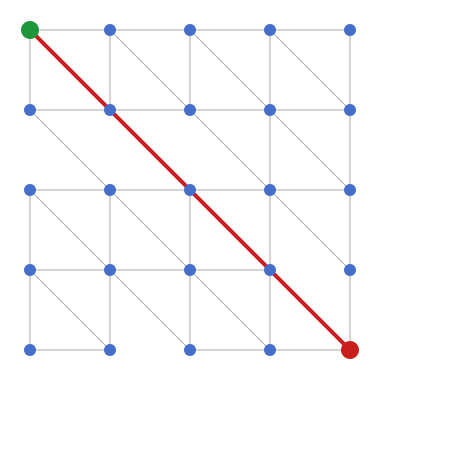

In [19]:
use plotters::prelude::*;

// Grille 5x5 : aretes grises, chemin optimal en rouge, source verte, destination rouge.
// Projection : fonction libre (evcxr exige 'static pour les closures).
fn proj_grille(i: usize, j: usize) -> (i32, i32) {
    let (pas, marge) = (80i32, 30i32);
    (marge + j as i32 * pas, marge + i as i32 * pas)
}
let px = proj_grille as fn(usize, usize) -> (i32, i32);

let (w_px, h_px) = (460u32, 460u32);
let mut svg = String::new();
{
    let root = SVGBackend::with_string(&mut svg, (w_px, h_px)).into_drawing_area();
    root.fill(&WHITE)?;
    for e in grille.edge_references() {
        let (a, b) = grille[e.source()];
        let (c, d) = grille[e.target()];
        root.draw(&PathElement::new(vec![px(a, b), px(c, d)], RGBColor(170, 170, 170)))?;
    }
    for w in chemin_opt.windows(2) {
        let (a, b) = grille[w[0]];
        let (c, d) = grille[w[1]];
        root.draw(&PathElement::new(vec![px(a, b), px(c, d)], RGBColor(200, 30, 30).stroke_width(4)))?;
    }
    for v in grille.node_indices() {
        let (i, j) = grille[v];
        root.draw(&Circle::new(px(i, j), 6, RGBColor(70, 110, 200).filled()))?;
    }
    root.draw(&Circle::new(px(0, 0), 9, RGBColor(30, 150, 60).filled()))?;
    root.draw(&Circle::new(px(4, 4), 9, RGBColor(200, 30, 30).filled()))?;
    root.present()?;
}
println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);

### Lecture de la figure

La grille porte 25 villes reliées par 51 arêtes (56 bruitées moins les 5 retirées), et le chemin optimal serpente du disque vert (source, coin nord-ouest) au disque rouge (destination, coin sud-est). Deux choses se voient : le chemin **n'est pas la diagonale** — le bruit et les retraits l'ont décalé vers des arêtes meilleur marché — et certaines arêtes manquantes de la trame régulière témoignent des retraits. C'est ce terrain irrégulier qui donne à l'heuristique euclidienne du travail : sur une trame parfaite à coût uniforme, elle n'aurait que la géométrie à proposer, et l'économie de la section 12.1 fondrait.


## 13. Réseau de collaborations

Le second banc réaliste du jumeau Python : 30 chercheurs répartis en trois communautés thématiques (IA, Bio, Physique) de 10, avec des liens intra-communauté denses (3 à 5 co-auteurs chacun, poids 1 à 4) et six liens inter-communautaires fixés à la main. La question de recherche : **PageRank et betweenness récompensent-ils les mêmes chercheurs ?** Les deux mesures sont calculées non pondérées, comme côté Python — le PageRank par l'organe (graphe symétrisé), la betweenness par le Brandes de la section 8 passé en mode sauts.


In [20]:
use std::collections::HashMap;
use petgraph::{algo, Graph, Directed, Undirected};
use petgraph::graph::NodeIndex;
use petgraph::visit::EdgeRef;
use rand::seq::index;
use rand::{rngs::StdRng, SeedableRng, Rng};

let mut rng = StdRng::seed_from_u64(123);

let mut collab: Graph<String, f64, Undirected> = Graph::new_undirected();
let mut cid: HashMap<String, NodeIndex> = HashMap::new();
for grp in ["IA", "Bio", "Phys"] {
    for i in 0..10 {
        let nom = format!("{}_0{}", grp, i);
        cid.insert(nom.clone(), collab.add_node(nom));
    }
}

// Liens intra : chaque chercheur choisit 3 a 5 co-auteurs dans sa communaute.
for grp in ["IA", "Bio", "Phys"] {
    for i in 0..10usize {
        let nb = rng.gen_range(3..6);
        for pos in index::sample(&mut rng, 9, nb) {
            let j = if pos >= i { pos + 1 } else { pos };
            let (a, b) = (format!("{}_0{}", grp, i), format!("{}_0{}", grp, j));
            if collab.find_edge(cid[&a], cid[&b]).is_none() {
                let w = rng.gen_range(1.0..5.0);
                collab.add_edge(cid[&a], cid[&b], w);
            }
        }
    }
}

// Liens inter-communautaires fixes (les futures passerelles).
for (a, b) in [
    ("IA_00", "Bio_05"), ("IA_03", "Bio_07"), ("IA_05", "Phys_02"),
    ("Bio_00", "Phys_08"), ("Phys_01", "IA_09"), ("Bio_02", "IA_07"),
] {
    collab.add_edge(cid[a], cid[b], 1.0);
}

// PageRank : l'organe exige un graphe dirige -> symetrisation.
let mut dir: Graph<String, (), Directed> = Graph::new();
let mut dmap: HashMap<NodeIndex, NodeIndex> = HashMap::new();
for v in collab.node_indices() {
    dmap.insert(v, dir.add_node(collab[v].clone()));
}
for e in collab.edge_references() {
    dir.add_edge(dmap[&e.source()], dmap[&e.target()], ());
    dir.add_edge(dmap[&e.target()], dmap[&e.source()], ());
}
let pr = algo::page_rank(&dir, 0.85_f32, 100);
let mut classe_pr: Vec<(f32, String)> = collab
    .node_indices()
    .map(|v| (pr[v.index()], collab[v].clone()))
    .collect();
classe_pr.sort_by(|x, y| {
    y.0.partial_cmp(&x.0)
        .unwrap_or(std::cmp::Ordering::Equal)
        .then(x.1.cmp(&y.1))
});

// Betweenness non ponderee : Brandes de la section 8, recopie en mode sauts.
fn betweenness<N>(g: &Graph<N, f64, Undirected>) -> HashMap<NodeIndex, f64> {
    let n = g.node_count();
    let mut cb: HashMap<NodeIndex, f64> = g.node_indices().map(|v| (v, 0.0)).collect();
    for s in g.node_indices() {
        let dist = algo::dijkstra(g, s, None, |_| 1.0);
        let mut atteints: Vec<NodeIndex> = dist.keys().copied().collect();
        atteints.sort_by(|a, b| {
            dist[a]
                .partial_cmp(&dist[b])
                .unwrap_or(std::cmp::Ordering::Equal)
                .then(a.index().cmp(&b.index()))
        });
        let mut sigma: HashMap<NodeIndex, f64> = g.node_indices().map(|v| (v, 0.0)).collect();
        sigma.insert(s, 1.0);
        let mut preds: HashMap<NodeIndex, Vec<NodeIndex>> = HashMap::new();
        for u in &atteints {
            for e in g.edges(*u) {
                let w = e.target();
                let du = dist[u];
                let dw = dist.get(&w).copied().unwrap_or(f64::INFINITY);
                if (dw - (du + 1.0)).abs() < 1e-9 {
                    *sigma.entry(w).or_insert(0.0) += sigma[u];
                    preds.entry(w).or_default().push(*u);
                }
            }
        }
        let mut delta: HashMap<NodeIndex, f64> = g.node_indices().map(|v| (v, 0.0)).collect();
        for u in atteints.iter().rev() {
            for p in preds.get(u).cloned().unwrap_or_default() {
                *delta.entry(p).or_insert(0.0) += sigma[&p] / sigma[u] * (1.0 + delta[u]);
            }
            if *u != s {
                *cb.entry(*u).or_insert(0.0) += delta[u];
            }
        }
    }
    for v in cb.values_mut() {
        *v /= ((n - 1) * (n - 2)) as f64;
    }
    cb
}

let bet = betweenness(&collab);
let mut classe_bet: Vec<(f64, String)> = collab
    .node_indices()
    .map(|v| (bet[&v], collab[v].clone()))
    .collect();
classe_bet.sort_by(|x, y| {
    y.0.partial_cmp(&x.0)
        .unwrap_or(std::cmp::Ordering::Equal)
        .then(x.1.cmp(&y.1))
});

let passerelles: Vec<&str> = vec![
    "IA_00", "Bio_05", "IA_03", "Bio_07", "IA_05", "Phys_02",
    "Bio_00", "Phys_08", "Phys_01", "IA_09", "Bio_02", "IA_07",
];

println!("reseau : {} chercheurs, {} collaborations", collab.node_count(), collab.edge_count());
println!("top 5 pagerank (popularite par citations) :");
for (s, nom) in classe_pr.iter().take(5) {
    println!("  {} : {:.4}", nom, s);
}
println!("top 5 betweenness (role passerelle) :");
for (s, nom) in classe_bet.iter().take(5) {
    println!("  {} : {:.4}", nom, s);
}
println!("passerelles (extremites des 6 liens inter) : {} chercheurs", passerelles.len());

reseau : 30 chercheurs, 98 collaborations


top 5 pagerank (popularite par citations) :


  IA_03 : 0.0458


  Phys_01 : 0.0440


  Bio_05 : 0.0422


  IA_05 : 0.0420


... (4 outputs left out)

  Phys_02 : 0.1415


  IA_05 : 0.1326


  Phys_01 : 0.1123


passerelles (extremites des 6 liens inter) : 12 chercheurs


### Lecture du résultat — popularité et pontage sont orthogonaux

Comparez les deux top 5 ligne à ligne : ils ne se recouvrent presque pas. Le sommet de la betweenness est une **passerelle** — une extrémité de lien inter-communauté, par laquelle transite tout plus court chemin qui franchit le pont — tandis que le sommet du PageRank est un chercheur **cité** au cœur de sa propre communauté, sans rôle de routage. PageRank récompense le voisinage, betweenness le rôle de relais : deux questions différentes, deux classements différents.

Et les cinq premiers de la betweenness sont tous des passerelles : la centralité de pontage détecte mécaniquement la structure communautaire que PageRank, mesure de flux global, lisse. C'est pourquoi une analyse de réseau réaliste **rapporte plusieurs centralités conjointement** — à contraster avec le réseau des six villes de la section 8, assez petit et dense pour que Paris domine les quatre mesures à la fois. Les valeurs précises dépendent du tirage (graine 123 : reproductibles en Rust, différentes de celles du jumeau Python) ; l'orthogonalité des deux classements, elle, est structurelle.


## 14. Exercices

Trois exercices, calqués sur les exemples guidés du jumeau Python. Les squelettes sont valides et s'exécutent tels quels (ils rendent « rien trouvé ») ; à vous de remplir les `TODO` en suivant les étapes et les indices. Les fonctions des cellules ne persistent pas : copiez dans votre cellule celles des sections 5, 8 ou 9 dont vous avez besoin.


### Exercice 1 — Plus court chemin dans un réseau de transport

**Objectif** : construire le réseau de transport en commun ci-dessous (10 stations, temps de trajet en minutes) et calculer le plus court chemin de `Station_A` à `Station_J` — temps total et nombre de stations traversées.

**Indices** : `Graph::<&str, f64>::new_undirected()` puis `add_edge` ; `algo::dijkstra` depuis `Station_A` ; remontée des prédécesseurs comme dans la fonction `chemin_min` de la section 5. Le chemin minimal passe par `Station_E` et vaut 21 minutes — vérifiez que votre résultat le retrouve.


In [21]:
// EXERCICE 1 : plus court chemin dans un reseau de transport
fn plus_court_chemin(liaisons: &[(&str, &str, f64)], depart: &str, arrivee: &str) -> Option<(f64, Vec<String>)> {
    // TODO etudiant :
    // Etape 1 : construire le Graph<&str, f64> et la table nom -> NodeIndex
    // Etape 2 : appeler algo::dijkstra depuis `depart`
    // Etape 3 : remonter les predecesseurs jusqu'a `depart` (cf. section 5)
    // Indice : tester chaque voisin u par dist(u) + poids(u, v) == dist(v)
    let _ = (liaisons, depart, arrivee);
    None
}

let stations: Vec<(&str, &str, f64)> = vec![
    ("Station_A", "Station_B", 4.0), ("Station_A", "Station_C", 7.0),
    ("Station_B", "Station_D", 5.0), ("Station_B", "Station_E", 9.0),
    ("Station_C", "Station_E", 3.0), ("Station_C", "Station_F", 8.0),
    ("Station_D", "Station_G", 6.0), ("Station_E", "Station_G", 4.0),
    ("Station_E", "Station_H", 5.0), ("Station_F", "Station_H", 2.0),
    ("Station_G", "Station_I", 3.0), ("Station_H", "Station_I", 6.0),
    ("Station_H", "Station_J", 7.0), ("Station_I", "Station_J", 4.0),
];

match plus_court_chemin(&stations, "Station_A", "Station_J") {
    Some((minutes, chemin)) => println!("chemin {:?} : {} min, {} stations", chemin, minutes, chemin.len()),
    None => println!("Exercice a completer : remplir plus_court_chemin (TODO ci-dessus)"),
}

Exercice a completer : remplir plus_court_chemin (TODO ci-dessus)


()

### Exercice 2 — Les trois grands brokers d'un réseau social

**Objectif** : sur le réseau social ci-dessous (3 communautés + liens inter), calculer la betweenness de chaque personne et retourner les trois plus grands brokers.

**Indices** : recopiez la fonction `betweenness` de la section 8 (mode sauts) dans votre cellule ; construisez le graphe avec des poids 1.0 ; triez par score décroissant (`sort_by` avec `partial_cmp`) et gardez trois éléments. Les têtes du classement sont les extrémités des liens inter-communautés — vérifiez que vos trois noms en font partie.


In [22]:
// EXERCICE 2 : les 3 grands brokers d'un reseau social
fn top3_pontes(liens: &[(&str, &str)]) -> Vec<(String, f64)> {
    // TODO etudiant :
    // Etape 1 : construire le graphe (poids 1.0)
    // Etape 2 : recopier la fn betweenness de la section 8 (mode sauts)
    // Etape 3 : trier par score decroissant et garder 3 couples (nom, score)
    let _ = liens;
    Vec::new()
}

let liens_sociaux: Vec<(&str, &str)> = vec![
    // communaute 1
    ("Alice", "Bob"), ("Alice", "Chloe"), ("Bob", "Chloe"), ("Bob", "David"),
    ("Chloe", "David"), ("David", "Emma"),
    // communaute 2
    ("Farid", "Giulia"), ("Giulia", "Hugo"), ("Farid", "Hugo"), ("Giulia", "Ines"),
    ("Hugo", "Ines"), ("Ines", "Jules"),
    // communaute 3
    ("Karim", "Lea"), ("Lea", "Marc"), ("Karim", "Marc"), ("Marc", "Nina"),
    ("Nina", "Karim"), ("Nina", "Oscar"), ("Oscar", "Marc"),
    // liens inter (ce sont eux qui font les brokers)
    ("David", "Farid"), ("Emma", "Karim"), ("Jules", "Marc"),
];

let top3 = top3_pontes(&liens_sociaux);
if top3.is_empty() {
    println!("Exercice a completer : remplir top3_pontes (TODO ci-dessus)");
} else {
    for (nom, score) in top3 {
        println!("{} : {:.3}", nom, score);
    }
}

Exercice a completer : remplir top3_pontes (TODO ci-dessus)


()

### Exercice 3 — Coupe minimale d'un réseau de pipelines

**Objectif** : sur le réseau de pipelines ci-dessous (3 sources, 3 destinations, 6 intermédiaires), calculer la **coupe minimale** et vérifier le théorème max-flow / min-cut : sa capacité égale le flot maximum.

**Indices** : ajoutez une super-source (capacité 999 vers `S1`, `S2`, `S3`) et un super-puits (`D1`, `D2`, `D3` vers 999) ; recopiez `edmonds_karp` de la section 9 pour saturer le réseau ; après saturation, les nœuds atteignables depuis la source dans le graphe **résiduel** forment la rive S — les arêtes de S vers le complément forment la coupe, dont on somme les capacités.


In [23]:
// EXERCICE 3 : coupe minimale d'un reseau de pipelines
fn coupe_minimale(caps: &[(&str, &str, f64)]) -> f64 {
    // TODO etudiant :
    // Etape 1 : ajouter super-source (999 -> S1, S2, S3) et super-puits (D1, D2, D3 -> 999)
    // Etape 2 : recopier edmonds_karp (section 9) et saturer le reseau
    // Etape 3 : BFS sur le residuel depuis la super-source -> rive S ;
    //           somme des capacites des aretes S -> complement
    // Indice : le resultat doit egaler le flot maximum (max-flow / min-cut).
    let _ = caps;
    0.0
}

let pipelines: Vec<(&str, &str, f64)> = vec![
    ("S1", "I1", 20.0), ("S1", "I2", 15.0), ("S2", "I2", 25.0), ("S2", "I3", 10.0),
    ("S3", "I3", 20.0), ("S3", "I4", 15.0),
    ("I1", "I5", 18.0), ("I2", "I5", 12.0), ("I2", "I6", 20.0), ("I3", "I6", 15.0),
    ("I4", "I6", 10.0),
    ("I5", "D1", 25.0), ("I5", "D2", 10.0), ("I6", "D2", 20.0), ("I6", "D3", 25.0),
    ("I4", "D3", 8.0),
];

let capacite = coupe_minimale(&pipelines);
if capacite == 0.0 {
    println!("Exercice a completer : remplir coupe_minimale (TODO ci-dessus)");
} else {
    println!("coupe minimale : {:.0} (a comparer au flot maximum)", capacite);
}

Exercice a completer : remplir coupe_minimale (TODO ci-dessus)


()

## À retenir

- **L'organe est petgraph** : structure de graphe, `dijkstra`, `astar`, `bellman_ford`, `page_rank`, `connected_components` viennent de la crate ; le carnet les appelle, il ne les recrée pas.
- **Ce que l'organe ne fournit pas se déclare, pas se cache** : betweenness (Brandes), closeness, reconstruction de chemins, flot par arête (Edmonds-Karp sur matrice résiduelle), modularité, matching — réimplémentés ici parce qu'aucun crate mûr ne les offre, et dits comme tels.
- **Le poids est une décision de modélisation** : Paris -> Toulouse passe par Bordeaux en kilomètres, par Lyon en sauts — même graphe, deux optima différents.
- **Une heuristique informative oriente la recherche** : A* évalue bien moins de nœuds que Dijkstra sur la grille bruitée, et le coût optimal est retrouvé **sur cette instance**, vérifié par l'organe — l'économie est mesurée, pas affirmée.
- **Saturée n'est pas contraignante** : le flot maximum vaut 80 t/j ; +1 sur `Depot_2 -> Client_X` ou `Usine_A -> Depot_1` le porte à 81, +1 sur `Depot_1 -> Client_X` ne change rien — seule la coupe minimale décide.
- **L'aléatoire est un type semé** : `StdRng::seed_from_u64` rend chaque banc reproductible à l'exécution près, là où un état global Python se partage par accident.


## Vérifiez votre compréhension

1. **Pourquoi le trajet pondéré Paris -> Toulouse passe-t-il par Bordeaux, quand le trajet non pondéré passe par Lyon ?**

   <details>
   <summary>Réponse</summary>

   Le poids d'une arête est une distance routière. Sans poids, un parcours se mesure en **nombre de sauts** : Paris -> Lyon -> Toulouse est le chemin le plus court en arêtes (2), Paris -> Bordeaux -> Toulouse le chemin le plus court en kilomètres (585 + 245 = 830, contre 465 + 540 = 1005 par Lyon). Les deux questions sont légitimes ; elles n'ont pas la même réponse.
   </details>

2. **Qu'est-ce que l'admissibilité de l'heuristique garantit exactement, et l'heuristique euclidienne la possède-t-elle sur les deux terrains du carnet ?**

   <details>
   <summary>Réponse</summary>

   Elle garantit que A* retrouve **l'optimum de Dijkstra** : `h(n) <= h*(n)` (l'estimation ne surestime jamais le coût réel restant) maintient la priorité `f = g + h` cohérente avec les coûts vrais. Le vol d'oiseau est admissible sur le réseau des six villes car les distances routières ne passent pas sous la ligne droite. Sur la grille bruitée à ±30%, en revanche, ce n'est **pas garanti** : une arête peut coûter 0,7 fois sa longueur. Le carnet vérifie donc l'optimalité sur l'instance semée par comparaison directe avec Dijkstra (`couts confondus : true`), sans en faire une propriété générale du bruit.
   </details>

3. **Le flot maximum vaut 80 t/j et `Depot_1 -> Client_X` est saturée à 25/25. La renforcer fait-il monter le flot ?**

   <details>
   <summary>Réponse</summary>

   **Non.** Saturée n'est pas contraignante : +1 sur `Depot_1 -> Client_X` laisse le flot à 80, car l'approvisionnement est bloqué en amont (`Usine_A -> Depot_1` est à 30/30). Les vrais goulots sont les arêtes de la **coupe minimale** — `Depot_2 -> Client_X` et `Usine_A -> Depot_1` portent le flot à 81 quand on les renforce. C'est le goulot qu'il faut tester, pas l'arête pleine.
   </details>

4. **Pourquoi le PageRank et la betweenness du réseau de collaborations ne récompensent-ils pas les mêmes chercheurs ?**

   <details>
   <summary>Réponse</summary>

   Le PageRank propage l'importance **le long des liens** : il récompense le voisinage dense (être co-auteur de chercheurs eux-mêmes cités). La betweenness compte les **plus courts chemins qui transitent** par un nœud : elle récompense le rôle de relais entre communautés — les extrémités des liens inter, par où passent tous les chemins qui franchissent le pont. Sur un réseau structuré en communautés, les deux classements sont presque disjoints : c'est l'information, pas un défaut.
   </details>


## Pour aller plus loin

- [Search-02b NetworkX Python](Search-02b-NetworkX.ipynb) — la théorie complète derrière chaque mesure de ce carnet, avec les quatre centralités, Louvain et le matching pondéré de networkx.
- [Search-02c QuikGraph](Search-02c-QuikGraph.ipynb) — le jumeau .NET du même parcours : la parité Python / C# / Rust sur un même corpus de gestes.
- [Search-03c Limited Discrepancy Search Rust](Search-03c-LimitedDiscrepancySearch-Rust.ipynb) et [Search-03d Weighted A* Rust](Search-03d-WeightedAstar-Rust.ipynb) — les autres carnets Rust de la série : recherche avec écarts bornés et A* pondéré.
- [petgraph sur docs.rs](https://docs.rs/petgraph) — la documentation de l'organe : chaque algorithme utilisé ici y est détaillé avec ses complexités.
- Brandes (2001), [arxiv:cond-mat/0109047](https://arxiv.org/abs/cond-mat/0109047) — l'algorithme de betweenness en O(VE) qui rend la mesure calculable sur de grands graphes.
